In [9]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax')

import time

from jax import numpy as jnp
from jax import random as jr
from jax import lax, vmap, pmap, jacfwd, jacrev, debug, device_put, jit
from tensorflow_probability.substrates.jax.distributions import MultivariateNormalFullCovariance as MVN
from typing import List, Optional, NamedTuple, Union
from jaxtyping import Array, Float, Int

# import tensorflow as tf
# tf.test.gpu_device_name()

import gaussfiltax.utils as utils
import gaussfiltax.inference as gf
from gaussfiltax.inference import ParamsUKF, _ukf_predict_nonadditive, PosteriorGaussianSumFiltered, _process_input, _get_params, swap_axes_on_values
from gaussfiltax.models import ParamsNLSSM, NonlinearSSM, ParamsBPF


import matplotlib.pyplot as plt
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [10]:
# Parameters
state_dim = 1
state_noise_dim = 1
emission_dim = 1
emission_noise_dim = 1
seq_length = 100
mu0 = 0.0 * jnp.zeros(state_dim)
q0 = jnp.zeros(state_noise_dim)
r0 = jnp.zeros(emission_noise_dim)
Sigma0 = 1.0 * jnp.eye(state_dim)
Q = 1.0 * jnp.eye(state_noise_dim)
R = 1.0 * jnp.eye(emission_noise_dim)

# ICASSP
# f1 = lambda x, q, u: (1-u) * x / 2.  + u * jnp.sin(10 * x) + q
f1 = lambda x, q, u: 20 * jnp.sin(10 * x) + q
g1 = lambda x, r, u:  0.01 * jnp.dot(x, x) + r
def g1lp(x,y,u):
    return MVN(loc = g1(x, r0, u), covariance_matrix = R).log_prob(y)


# Lorenz 63
def lorentz_63(x, sigma=10, rho=28, beta=2.667, dt=0.01):
    dx = dt * sigma * (x[1] - x[0])
    dy = dt * (x[0] * rho - x[1] - x[0] *x[2]) 
    dz = dt * (x[0] * x[1] - beta * x[2])
    return jnp.array([dx+x[0], dy+x[1], dz+x[2]])
f63 = lambda x, q, u: lorentz_63(x) + q

# stochastic growth model
f3 = lambda x, q, u: x / 2. + 25. * x / (1 + jnp.power(x, 2)) + q
g3 = lambda x, r, u: u * 0.8 * x + (1-u) * jnp.dot(x, x) + r 
def g3lp(x,y,u):
    return MVN(loc = g3(x, 0.0, u), covariance_matrix = R).log_prob(y)


# Stochastic Volatility
alpha = 0.91
sigma = 1.0
beta = 0.5
fsv= lambda x, q, u: alpha * x + sigma * q
gsv = lambda x, r, u: beta * jnp.exp(x/2) * r
def svlp(x,y,u):
    return MVN(loc = gsv(x, r0, u), covariance_matrix = gsv(x, 1.0, u)**2 * R).log_prob(y)

# Linear - Stochastic Volatility
alpha = 0.91
sigma = 5.0
beta = 0.5
glsv = lambda x, r, u: u * beta * jnp.exp(x/2) * r + (1-u) * (0.8 * x + r)
def lsvlp(x,y,u):
    return MVN(loc = glsv(x, r0, u), covariance_matrix = u * beta ** 2 * jnp.exp(x) * R + (1-u) * R).log_prob(y)

# Multivariate SV
Phi = 0.8 * jnp.eye(state_dim)
fmsv = lambda x, q, u: Phi @ x + q #((1-u) + 0.3*u)*q
gmsv = lambda x, r, u:  u * 0.5 * jnp.multiply(jnp.exp(x/2), r)
def msvlp(x,y,u):
    return MVN(loc = gmsv(x, r0, u), covariance_matrix = jnp.diag(jnp.exp(x/2.0)) @ R @ jnp.diag(jnp.exp(x/2.0))).log_prob(y)

# Linear - Multivariate SV
sigma = 5.0
beta = 0.5

H = 0.1 * jnp.eye(emission_dim, state_dim)
glmsv = lambda x, r, u: H @ x + r
# lambda x, r, u: 0 * beta * jnp.multiply(jnp.exp(x / sigma), r) + (1-0) * (H @ x + r)
def lmsvlp(x,y,u):
    # M = 0 * beta * jnp.diag(jnp.exp(x / sigma)) + (1-0) * jnp.eye(emission_dim)
    M = jnp.eye(emission_dim)
    return MVN(loc = glmsv(x, r0, u), covariance_matrix = M @ R @ M.T).log_prob(y)


# Linear-Gaussian SSM
A = 0.8 * jnp.eye(state_dim)
H = 0.1 * jnp.eye(emission_dim, state_dim)
fLG = lambda x, q, u: A @ x + q
gLG = lambda x, r, u: H @ x + r
gLGlp = lambda x,y,u: MVN(loc = gLG(x, 0.0, u), covariance_matrix = R).log_prob(y)

# Inputs
# inputs = 8. * jnp.cos(1.2 * jnp.arange(seq_length))
# sm = lambda x : jnp.exp(x) / (1+jnp.exp(x))
# inputs = sm(jnp.arange(seq_length)-50) # off - on gradually
# inputs = jnp.array([0]*int(seq_length/2) + [1]*int(seq_length/2)) # off - on
inputs = 1.0 * jnp.zeros(seq_length) # off
# inputs = vmap(lambda x: jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# inputs = 1.0 * jnp.ones(seq_length) # on

f = f3
g = g3
glp = g3lp


In [11]:
# # Parameters
# state_dim = 4
# state_noise_dim = 2
# emission_dim = 2
# emission_noise_dim = 2
# seq_length = 500
# mu0 = 1.0 * jnp.array([-0.05, 0.001, 0.7, -0.05])
# q0 = jnp.zeros(state_noise_dim)
# r0 = jnp.zeros(emission_noise_dim)
# Sigma0 = 1.0 * jnp.array([[0.1, 0.0, 0.0, 0.0],[0.0, 0.005, 0.0, 0.0],[0.0, 0.0, 0.1, 0.0],[0.0, 0.0, 0.0, 0.01]])
# Q = 1e-5 * jnp.eye(state_noise_dim)
# R = 25*1e-6 * jnp.eye(emission_noise_dim)

# dt = 0.5
# FCV = 1.0 * jnp.array([[1, dt, 0, 0],[0, 1, 0, 0],[0, 0, 1, dt],[0, 0, 0, 1]])
# acc = 0.5
# Omega = lambda x, acc: 0.1 * acc / jnp.sqrt(x[1]**2 + x[3]**2)
# FCT =  lambda x, a: jnp.array([[1, jnp.sin(dt * Omega(x, a)) / Omega(x, a), 0, -(1-jnp.cos(dt * Omega(x, a))) / Omega(x, a)],
#                             [0, jnp.cos(dt * Omega(x, a)), 0, -jnp.sin(dt * Omega(x, a))],
#                             [0, (1-jnp.cos(dt * Omega(x, a))) / Omega(x, a), 1, jnp.sin(dt * Omega(x, a)) / Omega(x, a)],
#                             [0, jnp.sin(dt * Omega(x, a)), 0, jnp.cos(dt * Omega(x, a))]])

# G = jnp.array([[0.5, 0],[1, 0],[0, 0.5],[0, 1]])
# fBOT = lambda x, q, u: FCV @ x + G @ q
# fManBOT = lambda x, q, u: (0.5*(u-1)*(u-2)*FCV - u*(u-2)*FCT(x, acc) + 0.5*u*(u-1) * FCT(x, -acc)) @ x + G @ q
# gBOT = lambda x, r, u: jnp.arctan2(x[2], x[0]) + r
# gBOT2 = lambda x ,r, u: jnp.array([jnp.arctan2(x[2], x[0]), jnp.sqrt(x[0]**2 + x[2]**2)]) + r
# gBOTlp = lambda x, y, u: MVN(loc = gBOT2(x, r0, u), covariance_matrix = R).log_prob(y)
# # inputs = jnp.zeros((seq_length, 1))
# inputs = jnp.array([1]*int(2*seq_length/5) + [0]*int(seq_length/5) + [2]*int(2*seq_length/5)) # changepoint inputs
# # inputs = vmap(lambda x: 2 * jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# # inputs = jr.choice(jr.PRNGKey(0), jnp.array([0, 1, 2]), shape = (seq_length, 1)) # random inputs

# f = fManBOT
# g = gBOT2
# glp = gBOTlp

In [12]:
params_bpf = ParamsBPF(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias=q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias=r0,
    emission_noise_covariance=R,
    emission_distribution_log_prob = glp
)

In [13]:
def measurement_update(key, params, nprt, m, cov, u, y):
    # sample new particles
    particles = MVN(m, cov).sample(nprt, key)
    # compute weights
    map_log_prob = vmap(params.emission_distribution_log_prob, in_axes=(0,None,None))
    lls = map_log_prob(particles, y, u)
    lls -= jnp.max(lls)
    weights = jnp.exp(lls)
    weights = weights / jnp.sum(weights)
    new_m = jnp.sum(weights[:, None] * particles, axis=0)
    new_cov = jnp.sum(weights[:, None, None] * (particles - new_m)[:, :, None] * (particles - new_m)[:, None, :], axis=0)
    return new_m, new_cov

def time_update(key, params, nprt, m, cov, u):
    # sample new particles
    particles = MVN(m, cov).sample(nprt, key)
    keys = jr.split(key, nprt)
    map_sample_particles = vmap(params.sample_dynamics_distribution, in_axes=(0,0,None))
    new_particles = map_sample_particles(keys, particles, u)
    new_m = jnp.mean(new_particles, axis=0)
    new_cov = jnp.sum((new_particles - new_m)[:, :, None] * (new_particles - new_m)[:, None, :], axis=0) / nprt
    return new_m, new_cov

def gaussian_sum_particle_filter(
    params: ParamsNLSSM,
    emissions: Float[Array, "ntime emission_dim"],
    num_components: int = 1,
    nprt: int = 100,
    key: jr.PRNGKey = jr.PRNGKey(0),
    inputs: Optional[Float[Array, "ntime input_dim"]] = None
    ) -> PosteriorGaussianSumFiltered:
    r"""Run an Gaussian sum filter, which is a mixture of (iterated) extended Kalman filters to produce the
    marginal likelihood and filtered state estimates.
    Args:
        params: model parameters.
        emissions: observation sequence.
        num_components: number of components in Gaussian sum approximation.
        num_iter: number of linearizations around posterior for update step (default 1).
        inputs: optional array of inputs.
        output_fields: list of fields to return in posterior object.
            These can take the values "filtered_means", "filtered_covariances",
            "predicted_means", "predicted_covariances", and "weights".
    Returns:
        post: posterior object.
    """
    num_timesteps = len(emissions)
    inputs = _process_input(inputs, num_timesteps)

    def _step(carry, t):
        pred_means, pred_covs, key = carry

        # Get parameters and inputs for time index t
        u = inputs[t]
        y = emissions[t]
        keys = jr.split(key, num_components+2)
        next_key = keys[0]
        

        # Condition on this emission
        filtered_means, filtered_covs = vmap(measurement_update, in_axes=(0, None, None, 0, 0, None, None))(keys[2:], params_bpf, nprt, pred_means, pred_covs, u, y)
       

        # Predict the next state
        pred_keys = jr.split(keys[1], num_components)
        pred_means, pred_covs = vmap(time_update, in_axes=(0, None, None, 0, 0, None))(pred_keys, params_bpf, nprt, filtered_means, filtered_covs, u)


        # Build carry and output states
        carry = (pred_means, pred_covs, next_key)
        outputs = {
            "means": filtered_means,
            "covariances": filtered_covs,
            "predicted_means": pred_means,
            "predicted_covariances": pred_covs
        }

        return carry, outputs

    initial_means = MVN(params.initial_mean, params.initial_covariance).sample(num_components, jr.PRNGKey(0))
    initial_covs = jnp.array([params.initial_covariance for i in range(num_components)])
    carry = (initial_means, initial_covs, key)

    _, outputs = lax.scan(_step, carry, jnp.arange(num_timesteps))
    outputs = swap_axes_on_values(outputs)
    posterior_filtered = PosteriorGaussianSumFiltered(
       **outputs,
    )

    return posterior_filtered

In [14]:
# initialization
model = NonlinearSSM(state_dim, state_noise_dim, emission_dim, emission_noise_dim)
params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

sim 1/10
key0:  [2467461003  428148500]
key:  [3186719485 3840466878]
       Time taken for GSF:  0.17268013954162598
       Time taken for UGSF:  0.4091031551361084
       Time taken for AGSF:  1.0474660396575928
       Time taken for UAGSF:  1.2272367477416992
       Time taken for BPF:  1.0834319591522217
       Time taken for GSPF:  0.7893271446228027
              GSF RMSE: 9.879264
              UGSF RMSE: 16.710588
              AGSF RMSE: 3.4514384
              UAGSF RMSE: 3.3807015
              BPF RMSE: 13.5832405
              GSPF RMSE: nan


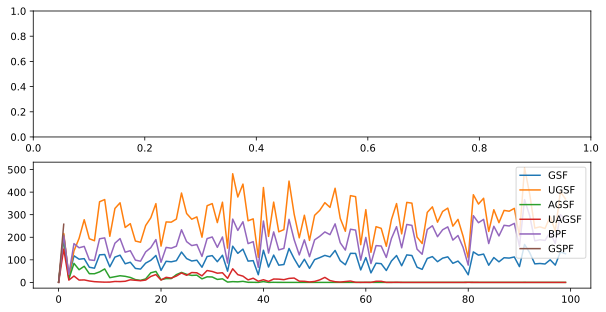

sim 2/10
key0:  [4038682467 4049047219]
key:  [1123993949 1633776119]
       Time taken for GSF:  0.1767590045928955
       Time taken for UGSF:  0.4375121593475342
       Time taken for AGSF:  1.1200718879699707
       Time taken for UAGSF:  1.2486131191253662
       Time taken for BPF:  1.1160998344421387
       Time taken for GSPF:  0.7357630729675293
              GSF RMSE: 8.8143215
              UGSF RMSE: 8.829216
              AGSF RMSE: 10.611579
              UAGSF RMSE: 16.823006
              BPF RMSE: 9.782858
              GSPF RMSE: nan


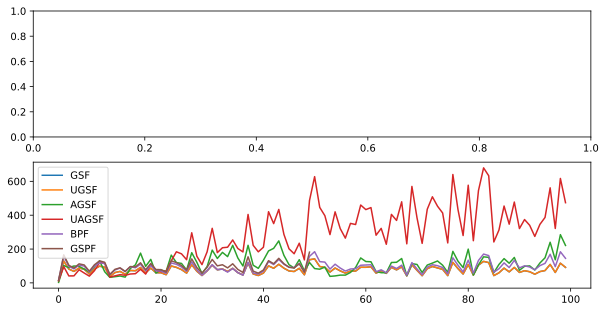

sim 3/10
key0:  [3295730785 1907469606]
key:  [2175656443 3507338041]
       Time taken for GSF:  0.2563631534576416
       Time taken for UGSF:  0.4185936450958252
       Time taken for AGSF:  1.0687401294708252
       Time taken for UAGSF:  1.2523581981658936
       Time taken for BPF:  1.0728328227996826
       Time taken for GSPF:  0.7393698692321777
              GSF RMSE: 9.492116
              UGSF RMSE: 8.860556
              AGSF RMSE: 15.357941
              UAGSF RMSE: 18.996565
              BPF RMSE: 9.846451
              GSPF RMSE: nan


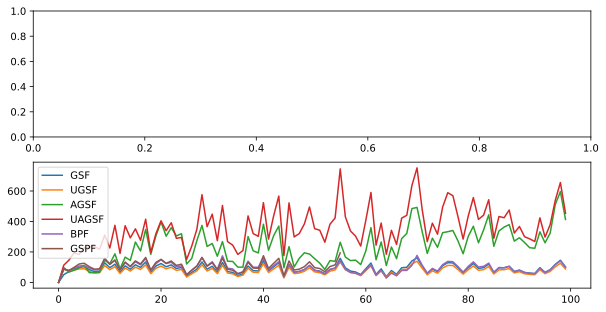

sim 4/10
key0:  [1795368326  584935165]
key:  [1120832370 3770592918]
       Time taken for GSF:  0.1667630672454834
       Time taken for UGSF:  0.40451502799987793
       Time taken for AGSF:  1.0359091758728027
       Time taken for UAGSF:  1.2264807224273682
       Time taken for BPF:  1.0722880363464355
       Time taken for GSPF:  0.7400088310241699
              GSF RMSE: 9.146093
              UGSF RMSE: 9.155969
              AGSF RMSE: 14.576255
              UAGSF RMSE: 11.48336
              BPF RMSE: 9.289683
              GSPF RMSE: nan


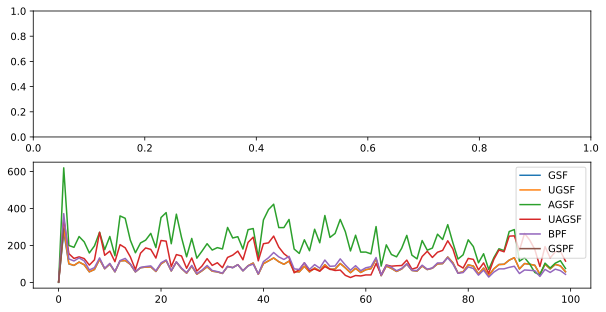

sim 5/10
key0:  [ 456292018 1165566599]
key:  [4102745572 3277364256]
       Time taken for GSF:  0.1652071475982666
       Time taken for UGSF:  0.402677059173584
       Time taken for AGSF:  1.1341609954833984
       Time taken for UAGSF:  1.228747844696045
       Time taken for BPF:  1.0924098491668701
       Time taken for GSPF:  0.760761022567749
              GSF RMSE: 11.127594
              UGSF RMSE: 11.341577
              AGSF RMSE: 16.28734
              UAGSF RMSE: 8.445621
              BPF RMSE: 10.435794
              GSPF RMSE: nan


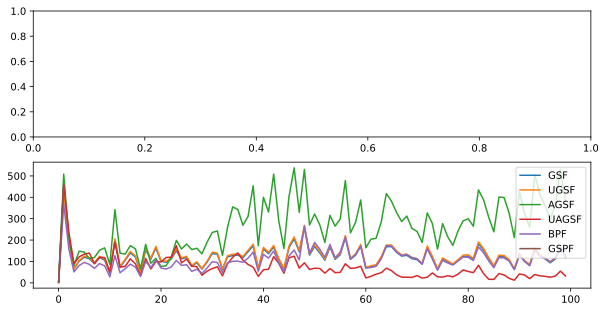

sim 6/10
key0:  [212254551 972031800]
key:  [4176427977  237722671]
       Time taken for GSF:  0.18555283546447754
       Time taken for UGSF:  0.40921592712402344
       Time taken for AGSF:  1.1574020385742188
       Time taken for UAGSF:  1.2164180278778076
       Time taken for BPF:  1.0616769790649414
       Time taken for GSPF:  0.7399129867553711
              GSF RMSE: 10.519716
              UGSF RMSE: 11.010478
              AGSF RMSE: 4.879182
              UAGSF RMSE: 5.548189
              BPF RMSE: 10.374761
              GSPF RMSE: nan


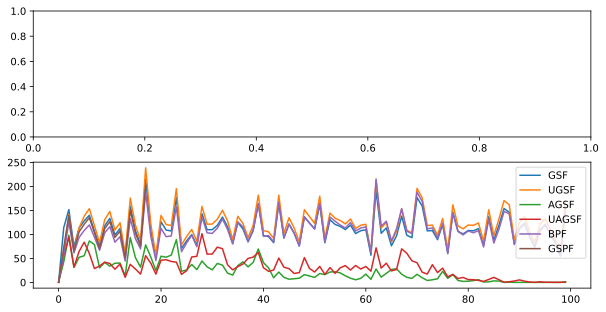

sim 7/10
key0:  [3685475569 1761638195]
key:  [1802191850  425137017]
       Time taken for GSF:  0.1628260612487793
       Time taken for UGSF:  0.39733028411865234
       Time taken for AGSF:  1.0335719585418701
       Time taken for UAGSF:  1.2192859649658203
       Time taken for BPF:  1.181175708770752
       Time taken for GSPF:  0.767003059387207
              GSF RMSE: 8.823986
              UGSF RMSE: 8.903075
              AGSF RMSE: 19.390001
              UAGSF RMSE: 10.048062
              BPF RMSE: 10.053841
              GSPF RMSE: nan


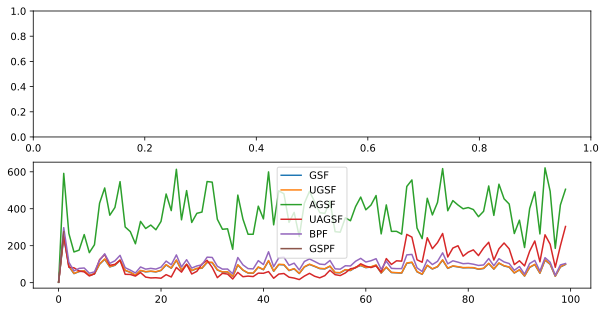

sim 8/10
key0:  [2004312237 1080707979]
key:  [3564672657 2387443400]
       Time taken for GSF:  0.19841575622558594
       Time taken for UGSF:  0.39702510833740234
       Time taken for AGSF:  1.0334818363189697
       Time taken for UAGSF:  1.2228331565856934
       Time taken for BPF:  1.065397024154663
       Time taken for GSPF:  0.734403133392334
              GSF RMSE: 16.362936
              UGSF RMSE: 5.983505
              AGSF RMSE: 9.949971
              UAGSF RMSE: 16.818651
              BPF RMSE: 9.524467
              GSPF RMSE: nan


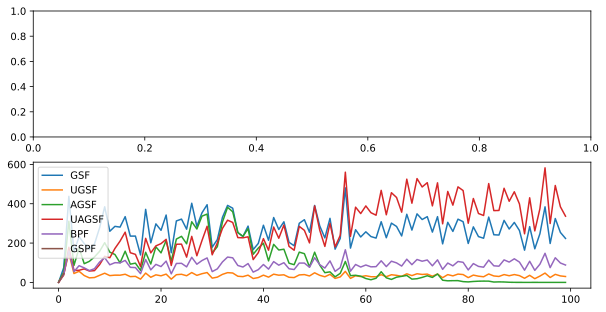

sim 9/10
key0:  [2372184986  857659058]
key:  [2470550142  587965772]
       Time taken for GSF:  0.16423916816711426
       Time taken for UGSF:  0.40046191215515137
       Time taken for AGSF:  1.0750679969787598
       Time taken for UAGSF:  1.2821378707885742
       Time taken for BPF:  1.0823919773101807
       Time taken for GSPF:  0.7654950618743896
              GSF RMSE: 8.83027
              UGSF RMSE: 9.853584
              AGSF RMSE: 11.530813
              UAGSF RMSE: 19.617819
              BPF RMSE: 9.97029
              GSPF RMSE: nan


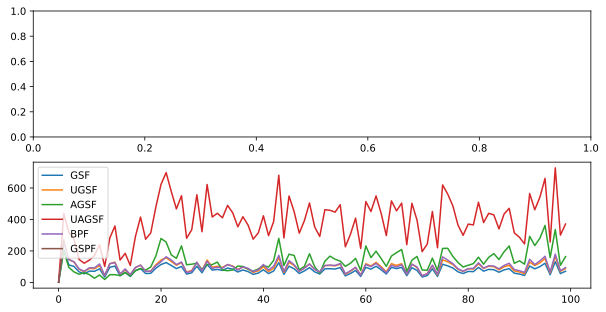

sim 10/10
key0:  [1353098956 1641448171]
key:  [ 605080484 2204356190]
       Time taken for GSF:  0.16379904747009277
       Time taken for UGSF:  0.40893077850341797
       Time taken for AGSF:  1.1746129989624023
       Time taken for UAGSF:  1.225714921951294
       Time taken for BPF:  1.0651330947875977
       Time taken for GSPF:  0.7808070182800293
              GSF RMSE: 11.056837
              UGSF RMSE: 12.312469
              AGSF RMSE: 14.189448
              UAGSF RMSE: 13.181137
              BPF RMSE: 10.4511595
              GSPF RMSE: nan


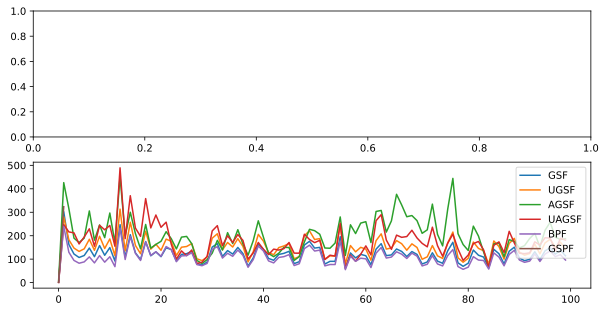

In [15]:
verbose = False
Nsim = 10
gsf_rmse = jnp.zeros(Nsim)
ugsf_rmse = jnp.zeros(Nsim)
agsf_rmse = jnp.zeros(Nsim)
uagsf_rmse = jnp.zeros(Nsim)
bpf_rmse = jnp.zeros(Nsim)
gspf_rmse = jnp.zeros(Nsim)

gsf_norm = jnp.zeros((Nsim, seq_length))
ugsf_norm = jnp.zeros((Nsim, seq_length))
agsf_norm = jnp.zeros((Nsim, seq_length))
uagsf_norm = jnp.zeros((Nsim, seq_length))
bpf_norm = jnp.zeros((Nsim, seq_length))
gspf_norm = jnp.zeros((Nsim, seq_length))

gsf_time = jnp.zeros(Nsim)
ugsf_time = jnp.zeros(Nsim)
agsf_time = jnp.zeros(Nsim)
uagsf_time = jnp.zeros(Nsim)
bpf_time = jnp.zeros(Nsim)
gspf_time = jnp.zeros(Nsim)
next_key = jr.PRNGKey(0)
for i in range(Nsim):
    print('sim {}/{}'.format(i+1, Nsim))
    # Generate Data
    key0, key, next_key = jr.split(next_key, 3)
    print('key0: ', key0)
    print('key: ', key)
    states, emissions = model.sample(params, key0, seq_length, inputs = inputs)

    # GSF
    M = 100
    tin = time.time()
    posterior_filtered_gsf = gf.gaussian_sum_filter(params, emissions, M, 1, inputs)
    point_estimate_gsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_gsf.means, posterior_filtered_gsf.weights), axis=0)
    tout = time.time()
    t_gsf= tout - tin
    print('       Time taken for GSF: ', tout - tin)

    # U-GSF
    tin = time.time()
    uparams = ParamsUKF(1,0,0)
    posterior_filtered_ugsf = gf.unscented_gaussian_sum_filter(params, uparams, emissions, M, 1, inputs)
    point_estimate_ugsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_ugsf.means, posterior_filtered_ugsf.weights), axis=0)
    tout = time.time()
    t_ugsf= tout - tin
    print('       Time taken for UGSF: ', tout - tin)

    # AGSF
    opt_args = (0.1, 0.1)
    num_components = [100, 5, 5]
    tin = time.time()
    posterior_filtered_agsf, aux_outputs = gf.speedy_augmented_gaussian_sum_filter(params, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)    
    point_estimate_agsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_agsf.means, posterior_filtered_agsf.weights), axis=0)
    tout = time.time()
    t_agsf= tout - tin
    print('       Time taken for AGSF: ', tout - tin)

    # U-AGSF
    tin = time.time()
    # posterior_filtered_uagsf, aux_outputs = gf.unscented_agsf(params, uparams, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)
    posterior_filtered_uagsf, aux_outputs = gf.speedy_unscented_agsf(params, uparams, emissions, num_components, key, opt_args, inputs=inputs)
    point_estimate_uagsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_uagsf.means, posterior_filtered_uagsf.weights), axis=0)
    tout = time.time()
    t_uagsf= tout - tin
    print('       Time taken for UAGSF: ', tout - tin)

    # BPF
    tin = time.time()
    num_particles = 100000

    params_bpf = ParamsBPF(
        initial_mean=mu0,
        initial_covariance=Sigma0,
        dynamics_function=f,
        dynamics_noise_bias=q0,
        dynamics_noise_covariance=Q,
        emission_function=g,
        emission_noise_bias=r0,
        emission_noise_covariance=R,
        emission_distribution_log_prob = glp
    )

    posterior_bpf = gf.bootstrap_particle_filter(params_bpf, emissions, num_particles, key, inputs, 1.0)
    point_estimate_bpf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_bpf["particles"], posterior_bpf["weights"]), axis=0)
    tout = time.time()
    t_bpf = tout - tin
    print('       Time taken for BPF: ', tout - tin)

    # GS-PF
    tin = time.time()
    num_particles = 100
    num_components = 100
    posterior_gspf = gaussian_sum_particle_filter(params, emissions, num_components, nprt = num_particles, key = key, inputs = inputs)
    point_estimate_gspf = jnp.sum(posterior_gspf.means, axis = 0) / num_components
    tout = time.time()
    t_gspf = tout - tin
    print('       Time taken for GSPF: ', tout - tin)

    # Computation of errors
    gsf_rmse = gsf_rmse.at[i].set(utils.rmse(point_estimate_gsf[:, (0,2)], states[:, (0,2)]))
    ugsf_rmse = ugsf_rmse.at[i].set(utils.rmse(point_estimate_ugsf[:, (0,2)], states[:, (0,2)]))
    agsf_rmse = agsf_rmse.at[i].set(utils.rmse(point_estimate_agsf[:, (0,2)], states[:, (0,2)]))
    uagsf_rmse = uagsf_rmse.at[i].set(utils.rmse(point_estimate_uagsf[:, (0,2)], states[:, (0,2)]))
    bpf_rmse = bpf_rmse.at[i].set(utils.rmse(point_estimate_bpf[:, (0,2)], states[:, (0,2)]))
    gspf_rmse = gspf_rmse.at[i].set(utils.rmse(point_estimate_gspf[:, (0,2)], states[:, (0,2)]))


    print('              GSF RMSE:', gsf_rmse[i])                                                                           
    print('              UGSF RMSE:', ugsf_rmse[i])
    print('              AGSF RMSE:', agsf_rmse[i])
    print('              UAGSF RMSE:', uagsf_rmse[i])
    print('              BPF RMSE:', bpf_rmse[i])
    print('              GSPF RMSE:', gspf_rmse[i])

    gsf_norm = gsf_norm.at[i].set(jnp.linalg.norm(point_estimate_gsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    ugsf_norm = ugsf_norm.at[i].set(jnp.linalg.norm(point_estimate_ugsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    agsf_norm = agsf_norm.at[i].set(jnp.linalg.norm(point_estimate_agsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    uagsf_norm = uagsf_norm.at[i].set(jnp.linalg.norm(point_estimate_uagsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    bpf_norm = bpf_norm.at[i].set(jnp.linalg.norm(point_estimate_bpf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    gspf_norm = gspf_norm.at[i].set(jnp.linalg.norm(point_estimate_gspf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)

    fig, axes = plt.subplots(2, 1, figsize=(10, 5))
    # axes[0].plot(states[:,0], label='True')
    # axes[0].plot(point_estimate_gsf[:,0], label='GSF')
    # axes[0].plot(point_estimate_ugsf[:,0], label='UGSF')
    # axes[0].plot(point_estimate_agsf[:,0], label='AGSF')
    # axes[0].plot(point_estimate_uagsf[:,0], label='UAGSF')
    # axes[0].plot(point_estimate_bpf[:,0], label='BPF')
    # axes[0].plot(emissions[:,0], label='Observed')
    # axes[0].legend()

    axes[1].plot(jnp.linalg.norm(point_estimate_gsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_ugsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_agsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_uagsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_bpf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_gspf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].legend(['GSF', 'UGSF', 'AGSF', 'UAGSF', 'BPF', 'GSPF'])

    plt.show()


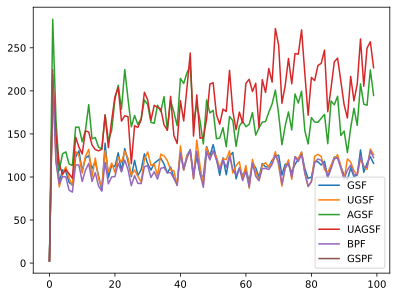

In [16]:
gsf_avg_norm = gsf_norm.sum(axis=0)/Nsim
ugsf_avg_norm = ugsf_norm.sum(axis=0)/Nsim
agsf_avg_norm = agsf_norm.sum(axis=0)/Nsim
uagsf_avg_norm = uagsf_norm.sum(axis=0)/Nsim
bpf_avg_norm = bpf_norm.sum(axis=0)/Nsim
gspf_avg_norm = gspf_norm.sum(axis=0)/Nsim


plt.plot(gsf_avg_norm, label='GSF')
plt.plot(ugsf_avg_norm, label='UGSF')
plt.plot(agsf_avg_norm, label='AGSF')
plt.plot(uagsf_avg_norm, label='UAGSF')
plt.plot(bpf_avg_norm, label='BPF')
plt.plot(gspf_avg_norm, label='GSPF')
plt.legend()
plt.show()